In [4]:
import pandas as pd
import matplotlib.pyplot as plt

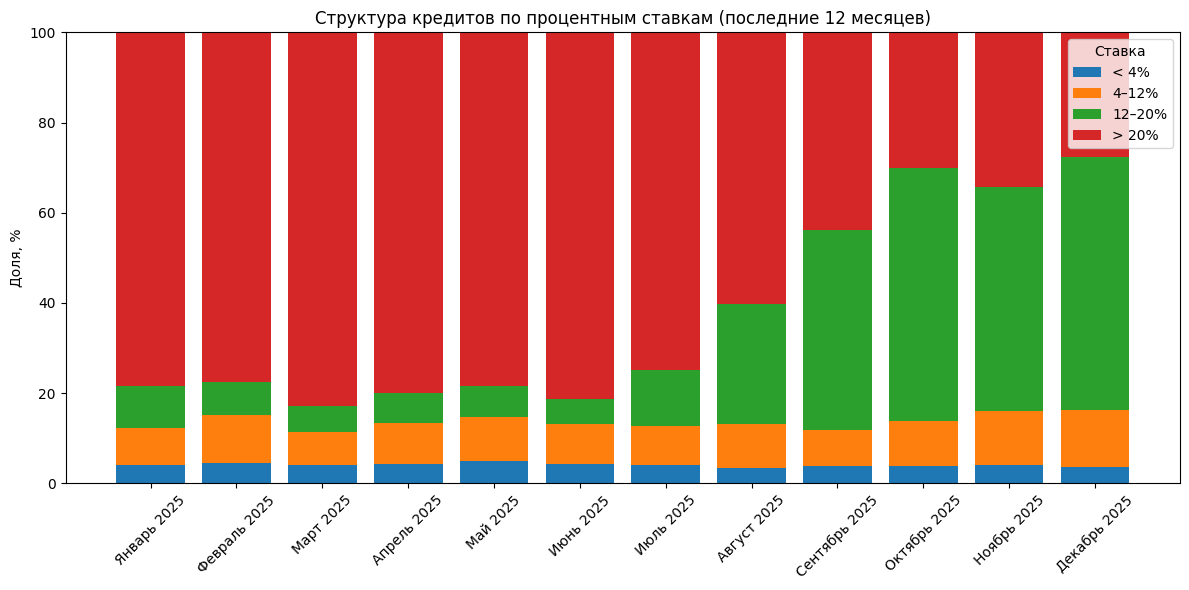

In [7]:
df = pd.read_excel(
    "02_06_loans_by_aggregated_interest_rate.xlsx",
    sheet_name="всего",
    header=None
)

df.columns = ["Период"] + df.iloc[2, 1:].tolist()
df = df.iloc[3:]
df = df.dropna(subset=["Период"])


df = df.tail(12).reset_index(drop=True)

df["< 4%"] = df["менее 4%"]
df["4–12%"] = df["4-7,99%"] + df["8-11,99%"]
df["12–20%"] = df["12-15,99%"] + df["16-19,99%"]
df["> 20%"] = df["20-23,99%"] + df["24% и выше"]

groups = ["< 4%", "4–12%", "12–20%", "> 20%"]

total = df[groups].sum(axis=1)
shares = df[groups].div(total, axis=0) * 100

labels = df["Период"].astype(str)

fig, ax = plt.subplots(figsize=(12, 6))
bottom = [0] * len(df)

for group in groups:
    ax.bar(labels, shares[group], bottom=bottom, label=group)
    bottom = bottom + shares[group]

ax.set_ylabel("Доля, %")
ax.set_title("Структура кредитов по процентным ставкам (последние 12 месяцев)")
ax.legend(title="Ставка")
ax.set_ylim(0, 100)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()